# Task 5 — Growth and seasonality in airline passengers

Completed Week 1 assignment. Every chart is followed by its design justification and interpretation.

**Run:** Python 3 with `pandas`, `numpy`, `matplotlib`, `seaborn`, and `IPython`. Use **Restart Kernel and Run All**. The original CSV is embedded, so no network or extra data files are needed.

**Data source:** [flights.csv](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/flights.csv), downloaded 30 September 2026 using the assignment script's source URL. These are historical teaching datasets, not current-world estimates.

**Chart policy:** finding-led titles, no dual y-axes, zero-based bars, meaningful colour and selective labels. The deliberately messy Task 2 chart is the required counterexample.

In [1]:
import base64, zlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
def finish(fig, note):
    fig.text(0.01, 0.012, note, fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.065, 1, 0.96))
    plt.show()

# Compressed CSV snapshot from the source linked above.
# Replace df with pd.read_csv("data/flights.csv") to use your local assignment file.
CSV_B64 = (
    'eJxl1stu2zAQBdB9v8ULcobPZYCiiwBtF/0CJxCSAokT+FHAf1+J946GRZdz+TAPJYq+L8fz4f3jdH09fB4vl+X0spwvX2JP/fB4'
    'PN2O5/shRkHwbXk6M2lIvh/Pz6+HqOzw8Hn+/XaI0q117SqRs91Oy9ozW/W2tiVO83B7uV2uXv9aPq/L+9NyXgcURD+frx8jiJz8'
    'x8cfdgkJydflmclYXg6TICNwgRQkFKSIkgLN1rp1ZQFB6lZtgho4jgKrJ0HmYnaBKgIXxITEBWnME12QMgIXZHahoDaUFBS11m2V'
    'wtmGwHpC0DvHUWD1JGgJ0S4onM8FqSBxQRmJuKBGBC5oAQkFXVFS0KK1bl3ZNgSC5ysQiHIaCiQJahdI6Ih2QefkLqgc5YI+2OqC'
    'XhC4wBIIRFlCIHiLdAhkHIpttiFIatUmKPwlE2AtOgu0IjKBxIjABdhOdYGE0SftAhlHZQ2mZ9CQmCCjpECqtW77zMEQlL1aBRqE'
    '4yjAs0yzIHdEu0AY7AIJHOUC9MkuwMPNLhAcp2yCUlFSULq1rl1xOjMEio9CpgCebAJNnMcFGvnbu6ByjAuUo1yA01ZcgNNUJkGt'
    'SCDQyBICjWqt6yqjzTYENVm1CpJ1pCCFjHoSZEYm0FAQuADHtLiAfeou4MZVFyhetGqCzBEUjM/6aL3bEioEScSqTVDYZgI8yzoJ'
    'Et7g6oLEPrtAA2dxAc5lcwE+r20SYGObCfCFa/8KGgT4tDYKcGIaBfiuNBPkwNb/BM0FOBhtEkQubxIMpd/JWgICF+Bk2J2c8NTs'
    'TtZerHVdpXAwBFWsWgUZ1P1OzljdfCcnbIDfySlwdS4onHMX4G0sfien8ZqX6U7WsXnF7uQ0bvpid3Iqe+uday68k7Pa3JugCNso'
    'KGMnynwn59AQ7QKb3AU9IHHB+i/nLwOkcSw='
)
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(CSV_B64))))
assert len(df) == 144
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing rows").to_frame())

Shape: (144, 3)


,year,month,passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121


,missing rows
year,0
month,0
passengers,0


## 1. Build a real ordered time axis

,date,passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


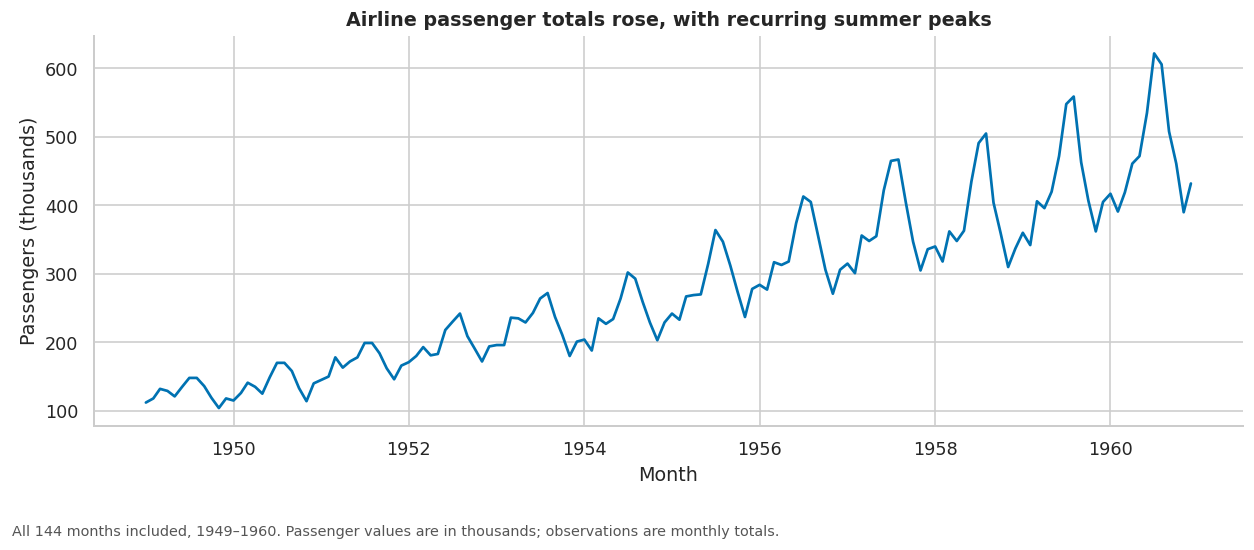

In [2]:
months=['January','February','March','April','May','June','July','August',
        'September','October','November','December']
month_numbers={month:i+1 for i,month in enumerate(months)}
assert df.isna().sum().sum()==0
assert set(df.month)==set(months)
df['month_number']=df.month.map(month_numbers)
df['date']=pd.to_datetime(dict(year=df.year,month=df.month_number,day=1))
df=df.sort_values('date').reset_index(drop=True)
assert not df.date.duplicated().any()
assert len(pd.date_range(df.date.min(),df.date.max(),freq='MS'))==len(df)
assert df.groupby('year').size().eq(12).all()
display(df[['date','passengers']].head())
fig,ax=plt.subplots(figsize=(11,5))
ax.plot(df.date,df.passengers,color=BLUE,lw=1.7)
ax.set(title='Airline passenger totals rose, with recurring summer peaks',
       xlabel='Month',ylabel='Passengers (thousands)')
ax.xaxis.set_major_locator(mdates.YearLocator(2));ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
finish(fig,'All 144 months included, 1949–1960. Passenger values are in thousands; observations are monthly totals.')

**Why a time-series line:** A true datetime axis orders months chronologically across year boundaries, exposing long-term growth and repeating peaks. It avoids alphabetical month order and accidental connections between unsorted records. The overall rise contains short-term dips; it is not a steadily increasing series.

## 2. Isolate the within-year seasonal pattern
Divide each month by its own year’s monthly mean and multiply by 100. This removes each year’s level, allowing comparison of **relative seasonality**. It does not fully detrend within-year growth.

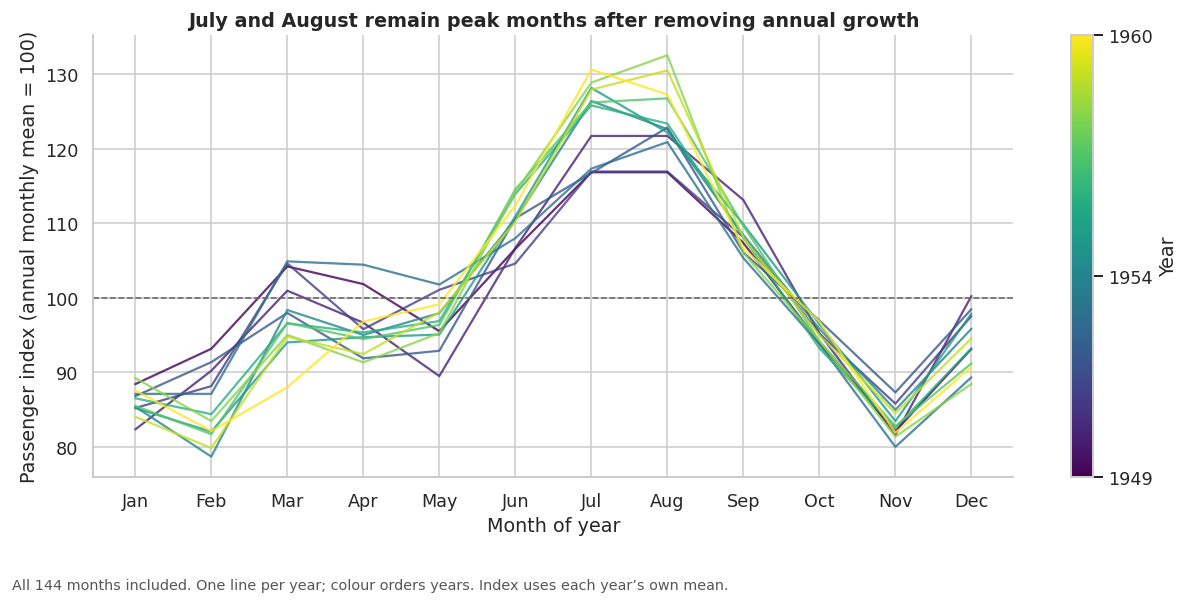

In [3]:
df['annual_monthly_mean']=df.groupby('year').passengers.transform('mean')
df['seasonal_index']=100*df.passengers/df.annual_monthly_mean
fig,ax=plt.subplots(figsize=(11,5.5))
years=sorted(df.year.unique());norm=plt.Normalize(min(years),max(years));cmap=plt.cm.viridis
for year,g in df.groupby('year'):
    ax.plot(g.month_number,g.seasonal_index,color=cmap(norm(year)),alpha=.8,lw=1.4)
ax.axhline(100,color='#666666',ls='--',lw=1)
ax.set_xticks(range(1,13),[m[:3] for m in months])
ax.set(title='July and August remain peak months after removing annual growth',
       xlabel='Month of year',ylabel='Passenger index (annual monthly mean = 100)')
sm=plt.cm.ScalarMappable(norm=norm,cmap=cmap)
fig.colorbar(sm,ax=ax,label='Year',ticks=[1949,1954,1960])
finish(fig,'All 144 months included. One line per year; colour orders years. Index uses each year’s own mean.')

**Why overlaid seasonal lines:** Aligning January–December reveals repeated seasonal timing. Normalization prevents later, larger years from dominating. Colour encodes chronological year through a continuous scale, avoiding a 12-entry legend. The recurring summer peak and late-autumn trough are clearer here than on the full timeline.

## 3. Which month is consistently busiest?
Count how many years each month is an annual maximum. **Count ties for both months**, rather than silently using only the first maximum.

,years_at_annual_peak_including_ties,mean_passengers_thousands
month,,
January,0,241.75
February,0,235.00
March,0,270.17
April,0,267.08
May,0,271.83
June,0,311.67
July,7,351.33
August,8,351.08
September,0,302.42


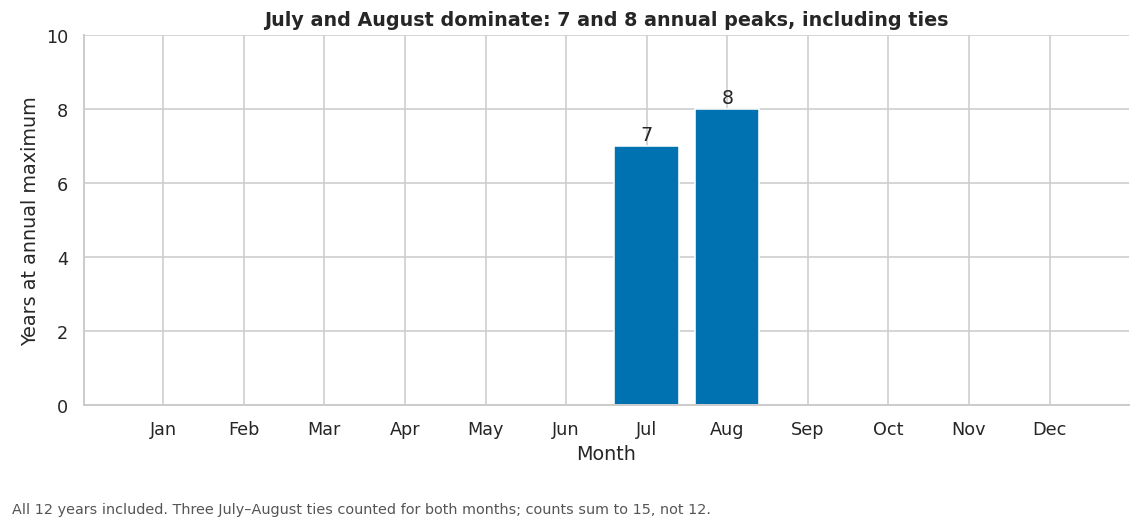

In [4]:
annual_max=df.groupby('year').passengers.transform('max')
winners=df[df.passengers.eq(annual_max)]
peak_counts=winners.groupby('month').size().reindex(months,fill_value=0)
monthly_means=df.groupby('month').passengers.mean().reindex(months)
display(pd.DataFrame({'years_at_annual_peak_including_ties':peak_counts,
                      'mean_passengers_thousands':monthly_means.round(2)}))
fig,ax=plt.subplots(figsize=(10,4.8))
bars=ax.bar([m[:3] for m in months],peak_counts.values,color=BLUE)
for bar,value in zip(bars,peak_counts.values):
    if value:ax.text(bar.get_x()+bar.get_width()/2,value+.15,str(value),ha='center')
ax.set(title='July and August dominate: 7 and 8 annual peaks, including ties',
       xlabel='Month',ylabel='Years at annual maximum',ylim=(0,10))
ax.set_yticks(range(0,11,2))
finish(fig,'All 12 years included. Three July–August ties counted for both months; counts sum to 15, not 12.')

**Why a zero-based bar chart:** Months are categories and peak frequency directly answers consistency, without allowing growth in later years to dominate the answer. Only the two nonzero bars are labelled.

**Answer:** There is no single winning month every year. August is at the annual maximum in **8 of 12 years** and July in **7**, with **3 ties**. July’s pooled average is slightly higher (351.33 vs 351.08 thousand), showing that “highest average” and “most often busiest” are different questions. The honest finding is that the **July–August pair** dominates; August wins the consistency measure.

## 4. Which chart belongs in a report?
For a short report asking **how passenger demand evolved from 1949 to 1960**, I would use chart 1: it communicates growth and recurring peaks together in one compact figure. Chart 2 removes absolute volume and adds analytical detail beyond that report’s main question. Chart 3 answers a scheduling question about the most frequent peak month, rather than the growth question. They are useful supporting analyses, but including all three would be redundant for that specific report. In a seasonal capacity-planning report I would instead choose chart 3, so the choice depends on the report’s purpose.

## 5. Is seasonality growing or is the airline just growing?
A larger absolute peak-to-trough swing does not by itself imply stronger relative seasonality. Compare `(annual maximum − annual minimum) / annual mean`: if this is stable while volume grows, the widening absolute swings are compatible with proportional (multiplicative) seasonality. If this rises, relative amplitude also grows. The normalized seasonal chart above already helps; the following extra diagnostic makes the yearly relative swing explicit.

,min,max,mean,relative_swing_pct
year,,,,
1949,104,148,126.67,34.74
1950,114,170,139.67,40.10
1951,145,199,170.17,31.73
1952,171,242,197.00,36.04
1953,180,272,225.00,40.89
1954,188,302,238.92,47.72
1955,233,364,284.00,46.13
1956,271,413,328.25,43.26
1957,301,467,368.42,45.06


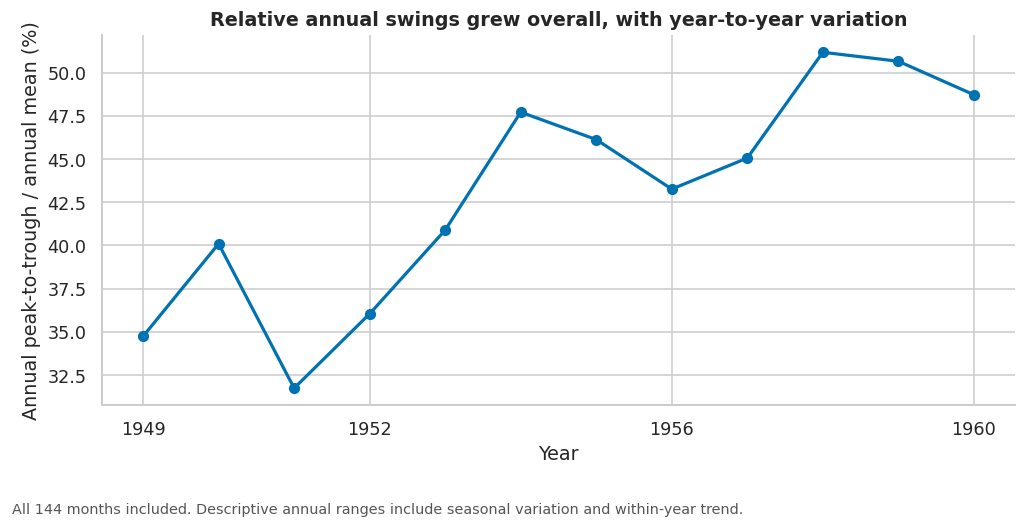

In [5]:
annual=df.groupby('year').passengers.agg(['min','max','mean'])
annual['relative_swing_pct']=100*(annual['max']-annual['min'])/annual['mean']
display(annual.round(2))
fig,ax=plt.subplots(figsize=(9,4.8))
ax.plot(annual.index,annual.relative_swing_pct,color=BLUE,marker='o',lw=2)
ax.set(title='Relative annual swings grew overall, with year-to-year variation',
       xlabel='Year',ylabel='Annual peak-to-trough / annual mean (%)')
ax.set_xticks([1949,1952,1956,1960])
finish(fig,'All 144 months included. Descriptive annual ranges include seasonal variation and within-year trend.')

**Why this diagnostic line:** Dividing the annual range by the annual mean removes the scale of the airline and produces one comparable value per year. The absolute annual range rose from 44 thousand passengers in 1949 to 232 thousand in 1960. Relative swings also rose overall, from about 35% to 49%, although they did not increase every year. Therefore airline growth alone does not fully explain the widening swings: relative variation increased too. This is suggestive, not a formal decomposition: yearly extremes include trend and noise. A log-scale time series or a detrended multiplicative seasonal decomposition would provide a stronger check on whether relative seasonal amplitude is stable.